In [1]:
import sys; sys.path.append("..")
import pandas as pd
from src.config import TEST_DIR, DATA_PROCESSED
from src.bootstrap import exact_ci_table

labels = pd.read_csv(DATA_PROCESSED / "label_names.csv").squeeze("columns").tolist()
d = pd.read_csv(TEST_DIR / "final_predictions.csv")

bang = exact_ci_table(d["y_true"], d["y_pred"], labels)
bang.to_csv(TEST_DIR / "final_per_class_exact_ci.csv", index=False)
bang

,lop,tp,so_mau_test,so_du_doan,recall_exact_thap,recall_exact_cao,precision_exact_thap,precision_exact_cao
0,ARP_poisioning,1511,1525,1521,0.9846,0.9950,0.9879,0.9968
1,DDOS_Slowloris,107,107,111,0.9661,1.0000,0.9103,0.9901
2,DOS_SYN_Hping,18018,18018,18018,0.9998,1.0000,0.9998,1.0000
3,MQTT_Publish,827,828,827,0.9933,1.0000,0.9955,1.0000
4,Metasploit_Brute_Force_SSH,7,7,7,0.5904,1.0000,0.5904,1.0000
5,NMAP_FIN_SCAN,6,6,6,0.5407,1.0000,0.5407,1.0000
6,NMAP_OS_DETECTION,400,400,400,0.9908,1.0000,0.9908,1.0000
7,NMAP_TCP_scan,200,200,202,0.9817,1.0000,0.9647,0.9988
8,NMAP_UDP_SCAN,512,517,513,0.9776,0.9969,0.9892,1.0000
9,NMAP_XMAS_TREE_SCAN,401,402,401,0.9862,0.9999,0.9908,1.0000


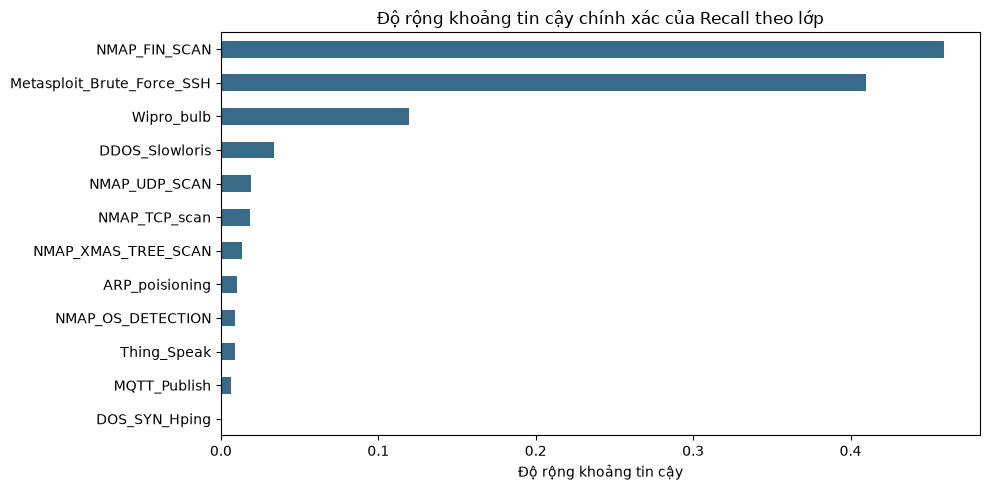

In [2]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

results = (Path('..') if Path.cwd().name == 'experiments' else Path('.')) / 'results'
data = pd.read_csv(results / 'test/final_per_class_exact_ci.csv').set_index('lop')
width = data['recall_exact_cao'] - data['recall_exact_thap']
fig, ax = plt.subplots(figsize=(10, 5))
width.sort_values().plot.barh(ax=ax, color='#386A89')
ax.set(title='Độ rộng khoảng tin cậy chính xác của Recall theo lớp', xlabel='Độ rộng khoảng tin cậy', ylabel='')
fig.tight_layout()
(results / 'figures').mkdir(exist_ok=True)
fig.savefig(results / 'figures/final_recall_ci_width.png', dpi=300, bbox_inches='tight')
plt.show()

In [3]:
for ten, n in [("Metasploit_SSH", 7), ("NMAP_FIN_SCAN", 6)]:
    recall = (n - 1) / n
    f1 = 2 * recall / (1 + recall)
    print(ten, "them 1 loi: F1 =", round(f1, 4), "Macro-F1 giam", round((1 - f1) / 12, 4))

cv_recall = {"Metasploit_SSH": 0.724, "NMAP_FIN_SCAN": 0.818}
xs = cv_recall["Metasploit_SSH"] ** 7 * cv_recall["NMAP_FIN_SCAN"] ** 6
print("Xac suat dung het ca hai lop neu ti le that bang uoc luong CV:", round(xs, 3))

Metasploit_SSH them 1 loi: F1 = 0.9231 Macro-F1 giam 0.0064
NMAP_FIN_SCAN them 1 loi: F1 = 0.9091 Macro-F1 giam 0.0076
Xac suat dung het ca hai lop neu ti le that bang uoc luong CV: 0.031
